# JOJA - Turn Ordinary Data Into Insights

## Contexte et objectif

Ce notebook présente une analyse exploratoire de données (EDA) d'un site de livraison de courses en ligne, à partir d'un dataset réel de plus de 3 millions de commandes et 200 000 utilisateurs. 

L'objectif pour nous est d'identifier des tendances et comportements d'achat exploitables afin de proposer des actions concrètes pour améliorer le business.

## Structure du notebook

1. **Rayon / Département** : diversité de l'assortiment et son lien avec le volume de commandes
2. **Produits** : bestsellers, comportement d'achat au niveau produit
3. **Evolution du comportement d'achat** : fidélité, taux de réachat, segmentation client
4. **Temporalité** : quand les clients commandent, et variations selon le profil client
5. **Machine Learning** : prédiction du réachat produit à partir de l'historique client

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "iframe_connected"
import sys
sys.path.append("..")

from plotly.subplots import make_subplots
from scipy.stats import pearsonr
from src.data_loader import get_data, load_raw_data
from src.features import enrich_dataframe, reorder_rate_by_group, reorder_evolution, add_cart_size, add_day_name
from src.features import enrich_dataframe

sns.set_theme(style="whitegrid", font_scale=1)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "#fafafa",
    "figure.facecolor": "white",
})

COLORS = {
    "occasionnel": "#a8bfc1",
    "typique":     "#4290ba",
    "fidèle":      "#1b3a4b",
    "accent":      "#3cc494",
    "grey":        "#6b7280",
}
PAL_SEGMENTS = [COLORS["occasionnel"], COLORS["typique"], COLORS["fidèle"]]

data = get_data(raw_dir="data/raw", processed_path="data/processed/merged_orders.parquet")
data = enrich_dataframe(data)

raw = load_raw_data(raw_dir="data/raw")
orders = raw["orders"]
order_products = raw["order_products"]
products = raw["products"]
aisles = raw["aisles"]
departments = raw["departments"]

print(f"Dataset: {data.shape[0]:,} lignes, {data.shape[1]} colonnes")

Chargement depuis le cache .parquet
Dataset: 32,434,489 lignes, 21 colonnes


## Préparation des données

Le projet s'appuie sur 5 tables sources (`orders`, `order_products`, `products`, `aisles`, `departments`), fusionnées en une seule table de travail (`data`) via `src/data_loader.py`. Le détail complet de l'exploration et du nettoyage est disponible dans `notebooks/01_data_loading_cleaning.ipynb`.
Cette section en résume les étapes et décisions clés.

### Nettoyage effectué

- **1 ligne corrompue** supprimée dans `order_products` (valeurs manquantes sur plusieurs colonnes simultanément, sur 10 737 547 lignes)
- **Aucun doublon** détecté dans les 5 tables
- Les valeurs manquantes de `days_since_prior_order` (206 209 sur `orders`) sont conservées : elles correspondent systématiquement à la première commande de chaque utilisateur (vérifié 100% de correspondance)

In [3]:
print(f"Table data : {data.shape[0]:,} lignes, {data.shape[1]} colonnes")
print(f"Valeurs manquantes restantes (hors days_since_prior_order) :")
print(data.drop(columns="days_since_prior_order").isnull().sum().sum())

Table data : 32,434,489 lignes, 21 colonnes
Valeurs manquantes restantes (hors days_since_prior_order) :
14397049


### Couverture des données

Le fichier `order_products.csv` ne couvre qu'un sous-ensemble des commandes de `orders.csv` : environ 1 064 689 commandes sur 3,4 millions, mais 92,1% des utilisateurs (189 980 sur 206 209) restent représentés avec une partie de leur historique.
Cette limitation, documentée en détail dans le brouillon d'exploration, n'invalide pas la représentativité des analyses menées sur `data`.

### Segmentation client

Les clients sont répartis en 3 segments selon leur nombre total de commandes, basé sur les quartiles observés (et non un seuil arbitraire) :

| Segment | Nombre de commandes | % des utilisateurs |
|---|---|---|
| Occasionnel | ≤ 6 | 25% |
| Typique | 7 à 20 | 50% |
| Fidèle | > 20 | 25% |

Cette segmentation est calculée automatiquement via `add_customer_segment()` dans `src/features.py`, et appliquée à `data` par `enrich_dataframe()`.

# I. Rayon / Département

**Objectif** : Comprendre comment les produits sont répartis entre rayons et départements, et si cette répartition (diversité, volume de commandes) influence les habitudes d'achat des clients.

**Questions à traiter** :

1. Combien de produits uniques existent par rayon/département ?
2. Y a-t-il un lien entre la diversité de produits d'un rayon et son volume de commandes ?
3. Dans un panier, combien de produits de différents départements/rayons peut-on trouver, et cette diversité diffère-t-elle selon le segment client ?

**Impact business attendu** : Déterminer si l'organisation du catalogue 
en ligne influence les commandes, afin d'identifier les rayons à mettre 
en avant ou à réévaluer en termes d'assortiment.

### Note méthodologique : les catégories "missing" et "other"

Deux catégories techniques ont été identifiées parmi les rayons et départements : "missing" et "other", qui ne correspondent pas à de vrais rayons physiques du site, mais regroupent des produits dont la catégorisation d'origine n'était pas renseignée dans les données sources.

**Vérification effectuée :** 
Un vrai département contient plusieurs rayons distincts ; "missing" et "other" n'en contiennent chacun qu'un seul, une structure anormale confirmée par un comptage systématique. 
Les produits de ces catégories ont par ailleurs des noms parfaitement renseignés (ex : "Organic Honeycrisp Apples", "Rescue Remedy"), écartant un problème de fiabilité sur les produits eux-mêmes.

**Décision :** 
Ces catégories représentent un poids non négligeable du catalogue (~2,5% et ~1,1% des produits référencés) mais un poids marginal des commandes réelles (0,21% et 0,11% des lignes de `data`, seulement 10 utilisateurs concernés exclusivement sur ~206 000). Elles sont donc **conservées** dans l'analyse (aucune donnée de vente n'est supprimée), mais **signalées visuellement** dans les graphiques concernés plutôt que mélangées aux vrais rayons.

## Question 1 : Combien de produits uniques existent par rayon/département ?

Pour répondre à cette question, on compte le nombre de produits uniques 
(`.nunique()`) par rayon et par département, à partir du catalogue `products` (et non de `data`, qui ne reflète que les produits effectivement commandés, pas le catalogue complet).

In [4]:
products_full = products.merge(aisles, on="aisle_id", how="left")
products_full = products_full.merge(departments, on="department_id", how="left")

products_per_aisle = products_full.groupby("aisle")["product_id"].nunique().sort_values(ascending=False)
products_per_dept = products_full.groupby("department")["product_id"].nunique().sort_values(ascending=False)

Le treemap ci-dessous visualise la hiérarchie département → rayon. Il 
est interactif et pleinement lisible dans l'export HTML du notebook.

In [6]:
fig = px.treemap(
    products_full,
    path=["department", "aisle"],
    title="Répartition des produits uniques par département et rayon",
)

fig.update_traces(textinfo="label+value")
fig.show()

**Note technique :** 
GitHub n'affiche pas correctement le JavaScript nécessaire aux graphiques Plotly dans son aperçu de notebook. Les graphiques statiques ci-dessous (matplotlib) garantissent un rendu fiable dans tous les environnements.

### Visualisation : Bar chart horizontal top 20 rayons et Bar chart horizontal départements

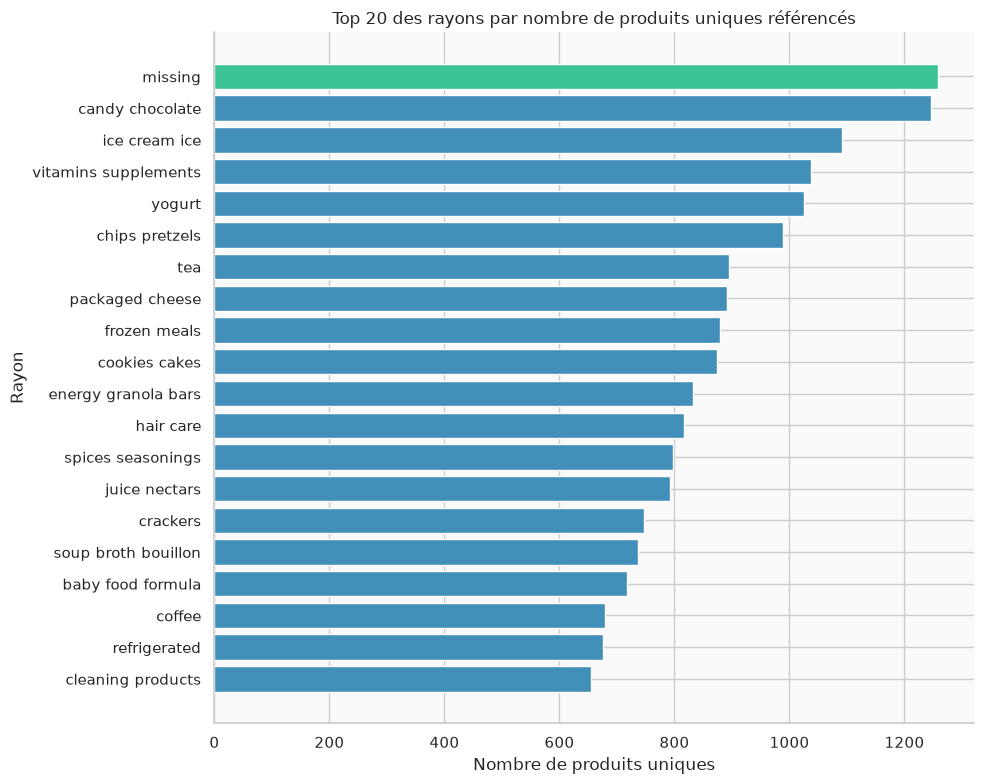

In [7]:
top_n = 20
top_aisles = products_per_aisle.head(top_n).reset_index()
top_aisles.columns = ["aisle", "product_count"]

colors = [COLORS["accent"] if aisle in ["missing", "other"] else COLORS["typique"] for aisle in top_aisles["aisle"]]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top_aisles["aisle"][::-1], top_aisles["product_count"][::-1], color=colors[::-1])
ax.set_xlabel("Nombre de produits uniques")
ax.set_ylabel("Rayon")
ax.set_title(f"Top {top_n} des rayons par nombre de produits uniques référencés")

plt.tight_layout()
plt.show()

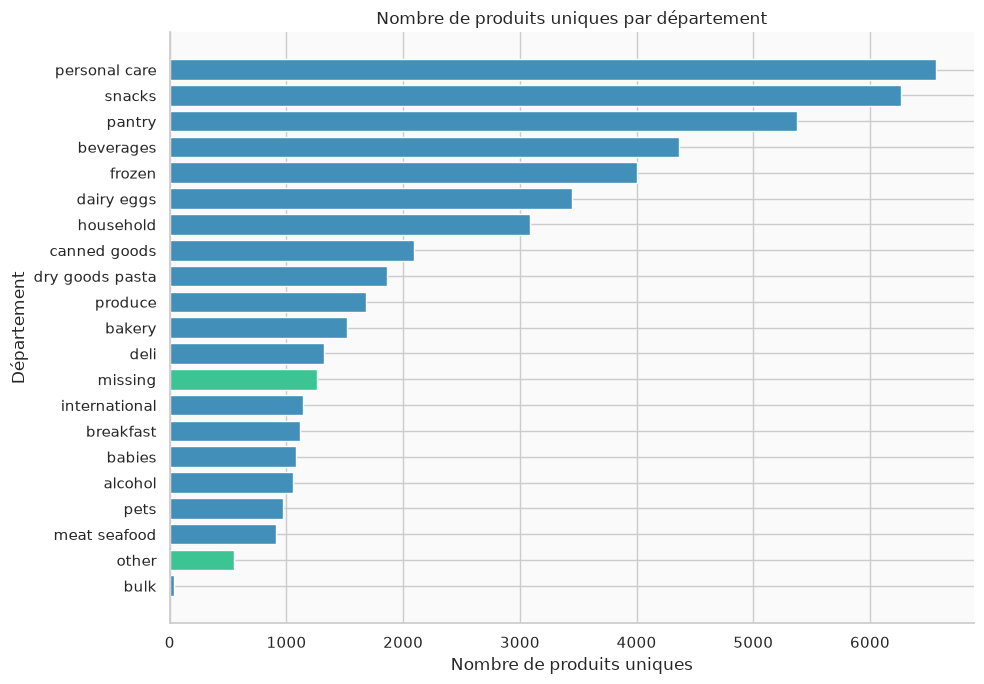

In [8]:
products_per_dept = products_full.groupby("department")["product_id"].nunique().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
colors_dept = [COLORS["accent"] if dept in ["missing", "other"] else COLORS["typique"] for dept in products_per_dept.index]
ax.barh(products_per_dept.index[::-1], products_per_dept.values[::-1], color=colors_dept[::-1])
ax.set_xlabel("Nombre de produits uniques")
ax.set_ylabel("Département")
ax.set_title("Nombre de produits uniques par département")

plt.tight_layout()
plt.show()

**Réponse à la question :** 
le nombre de produits uniques référencés varie fortement d'un rayon et d'un département à l'autre. Au niveau département, "personal care" (17 rayons), "snacks", "pantry" et "beverages" sont les plus fournis en diversité de rayons, tandis que des départements comme "pets", "meat seafood" ou "deli" n'en comptent que 2 à 5.

Au niveau rayon, "candy chocolate" (1246 produits) domine largement, suivi de "vitamins supplements" (1038) et "hair care" (816) contre certains rayons très restreints comme "meat seafood" ou "pets", qui n'affichent que quelques dizaines de produits.

**Implication business :** 
Cette forte disparité soulève la question de savoir si elle reflète une vraie différence de demande client, ou si certains rayons sont structurellement sous-fournis par rapport à leur potentiel de vente. 
C'est précisément ce que la question suivante (diversité de produits vs volume de commandes) va permettre de vérifier.

## Question 2 : Diversité de produits et volume de commandes

**Question :** 
Y a-t-il un lien entre la diversité de produits d'un rayon et son volume de commandes ?

**Hypothèse à tester :** 
Il existe une corrélation entre la diversité de produits référencés dans un rayon et son volume de commandes.

### Pourquoi exclure "missing" et "other" de ce calcul

Une corrélation mesure si deux variables suivent une même logique d'évolution. "missing" et "other" regroupent des produits sans lien thématique cohérent (contrairement aux vrais rayons), et leur inclusion risquerait de fausser le coefficient de corrélation — en particulier parce que "missing" (1258 produits) est un point extrême qui pourrait influencer le résultat de façon disproportionnée. Ces catégories restent néanmoins visibles ailleurs dans l'analyse, elles ne sont 
exclues que localement pour ce test statistique précis.

On construit deux mesures par rayon : la diversité de produits 
(catalogue) et le volume de commandes (comportement d'achat réel).

In [9]:
diversity_per_aisle = products_full[products_full["aisle"] != "other"]
diversity_per_aisle = diversity_per_aisle[diversity_per_aisle["aisle"] != "missing"]
diversity_per_aisle = diversity_per_aisle.groupby("aisle")["product_id"].nunique()
diversity_per_aisle.name = "product_diversity"

volume_per_aisle = data[~data["aisle"].isin(["missing", "other"])]
volume_per_aisle = volume_per_aisle.groupby("aisle")["product_id"].count()
volume_per_aisle.name = "order_volume"

aisle_stats = pd.concat([diversity_per_aisle, volume_per_aisle], axis=1).reset_index()
aisle_stats.head()

,aisle,product_diversity,order_volume
0,air fresheners candles,355,19851
1,asian foods,605,166607
2,baby accessories,44,8160
3,baby bath body care,132,8581
4,baby food formula,718,382456


Pour tester notre hypothèse, on utilise `scipy.stats`, la librairie de référence en Python pour les calculs statistiques (tests d'hypothèses, distributions de probabilité, corrélations...). On calcule ici le coefficient de corrélation de Pearson entre nos deux variables.

In [10]:
correlation, p_value = pearsonr(aisle_stats["product_diversity"], aisle_stats["order_volume"])
print(f"Coefficient de corrélation de Pearson : {correlation:.3f}")
print(f"P-value : {p_value:.5f}")

Coefficient de corrélation de Pearson : 0.299
P-value : 0.00050


**Résultat du test statistique :**
- Coefficient de corrélation de Pearson : 0,299 
(Correspond à un chiffre entre -1 et +1 qui mesure à quel point deux variables évoluent ensemble, plus il est proche de 1 plus le lien est fort)
- P-value : 0,00051 (< 0,05, donc statistiquement significatif autrement dit, il y a moins de 0,1% de chances que cette corrélation soit due au hasard)

**Interprétation :** 
Il existe bien une corrélation positive entre la diversité de produits d'un rayon et son volume de commandes, et cette relation est statistiquement significative (peu probable qu'elle soit due au hasard). 
Cependant, la force de cette corrélation reste faible à modérée (0,299 sur une échelle de -1 à +1, où 0 signifierait aucun lien et 1 un lien 
parfait) : la diversité de produits n'explique qu'une partie limitée 
des écarts de volume entre rayons. 
D'autres facteurs (prix, habitudes d'achat, fréquence de consommation 
du type de produit) jouent probablement un rôle au moins aussi 
important.

Le nuage de points ci-dessous permet de visualiser cette relation.

In [11]:
fig = px.scatter(
    aisle_stats,
    x="product_diversity",
    y="order_volume",
    hover_name="aisle",
    title="Diversité de produits vs volume de commandes, par rayon",
    labels={"product_diversity": "Nombre de produits uniques", "order_volume": "Volume de commandes"},
    trendline="ols",
)
fig.show()

**Note technique :** 
Comme pour la question précédente, le graphique interactif ci-dessus s'affiche pleinement dans l'export HTML, tandis que la version statique ci-dessous garantit un rendu fiable sur GitHub.

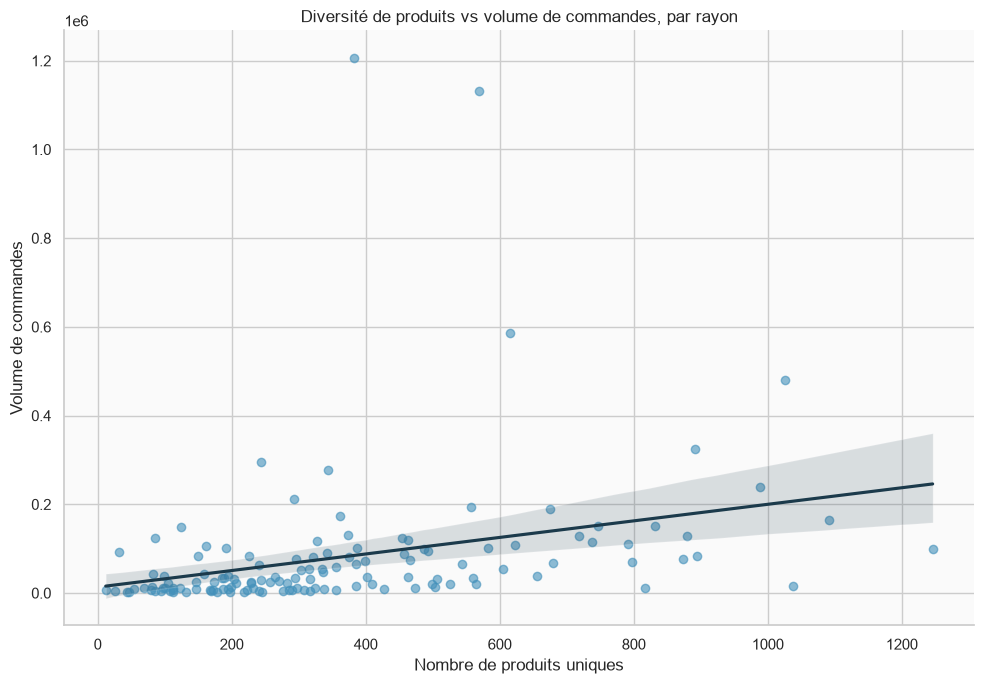

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.regplot(
    data=aisle_stats,
    x="product_diversity",
    y="order_volume",
    scatter_kws={"alpha": 0.6, "color": COLORS["typique"]},
    line_kws={"color": COLORS["fidèle"]},
    ax=ax
)
ax.set_xlabel("Nombre de produits uniques")
ax.set_ylabel("Volume de commandes")
ax.set_title("Diversité de produits vs volume de commandes, par rayon")

plt.tight_layout()
plt.show()

Le nuage de points confirme visuellement la corrélation faible mesurée, la tendance générale est positive (ligne de tendance croissante), mais la majorité des rayons se concentrent avec un volume de commandes modéré, quelle que soit leur diversité.

Trois rayons se démarquent nettement avec un volume de commandes très supérieur au reste : **fresh fruits** (382 produits, plus d'1,2 million de commandes), **fresh vegetables** (569 produits, plus d'1,1 million de commandes), et **packaged vegetables fruits** (615 produits, environ 585 000 commandes). Ces rayons de produits frais, à consommation quotidienne et récurrente, génèrent un volume de commandes très élevé malgré une diversité de produits pourtant modérée, ce qui explique en partie la faiblesse de la corrélation globale.

**Conclusion :** 
La diversité de produits joue un rôle réel mais limité dans le volume de commandes d'un rayon. D'autres facteurs, comme la fréquence de consommation naturelle du type de produit (produits essentiels vs produits occasionnels), semblent avoir un poids au moins aussi important.

## Question 3 : Diversité de panier et segment client

**Question :** 
Dans un panier, combien de produits de différents départements/rayons peut-on trouver, et cette diversité diffère-t-elle selon le segment client ?

**Hypothèse à tester :** 
On suppose qu'un client plus fidèle (ayant commandé plus fréquemment) a statistiquement plus d'occasions d'explorer le site, et pourrait donc présenter une diversité de panier plus élevée que les clients occasionnels.

**Précision méthodologique :** 
L'analyse mesure la diversité d'un panier donné(une commande individuelle) pas la diversité cumulée sur l'ensemble de l'historique d'achat d'un client. 

In [ ]:
orders_diversity = data.drop_duplicates(subset="order_id")[["order_id", "dept_per_order", "customer_segment"]]
diversity_by_segment = orders_diversity.groupby("customer_segment", observed=True)["dept_per_order"].describe()
diversity_by_segment

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
occasionnel,141236.0,4.676187,2.594878,1.0,3.0,4.0,6.0,17.0
typique,325665.0,4.783772,2.594522,1.0,3.0,4.0,6.0,17.0
fidèle,597788.0,4.721697,2.511192,1.0,3.0,4.0,6.0,17.0


On regarde maintenant au niveau rayon, plus granulaire :

In [ ]:
orders_diversity_aisle = data.drop_duplicates(subset="order_id")[["order_id", "aisles_per_order", "customer_segment"]]
diversity_by_segment_aisle = orders_diversity_aisle.groupby("customer_segment", observed=True)["aisles_per_order"].describe()
diversity_by_segment_aisle

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
occasionnel,141236.0,7.082500,4.774840,1.0,3.0,6.0,10.0,42.0
typique,325665.0,7.303742,4.832166,1.0,4.0,6.0,10.0,47.0
fidèle,597788.0,7.272013,4.707685,1.0,4.0,6.0,10.0,51.0


In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Diversité par département", "Diversité par rayon"))

for segment in ["occasionnel", "typique", "fidèle"]:
    fig.add_trace(
        go.Box(y=orders_diversity[orders_diversity["customer_segment"] == segment]["dept_per_order"], name=segment, boxpoints=False),
        row=1, col=1
    )

for segment in ["occasionnel", "typique", "fidèle"]:
    fig.add_trace(
        go.Box(y=orders_diversity_aisle[orders_diversity_aisle["customer_segment"] == segment]["aisles_per_order"], name=segment, showlegend=False, boxpoints=False),
        row=1, col=2
    )

fig.update_yaxes(title_text="Nombre de départements", row=1, col=1)
fig.update_yaxes(title_text="Nombre de rayons", row=1, col=2)

fig.update_layout(title="Diversité du panier par segment client", showlegend=False, height=500)
fig.show()

**Note technique :** comme pour la question précédente, le graphique interactif (Plotly) ci-dessus s'affiche pleinement dans l'export HTML du notebook, tandis que la version statique ci-dessous garantit un rendu fiable.

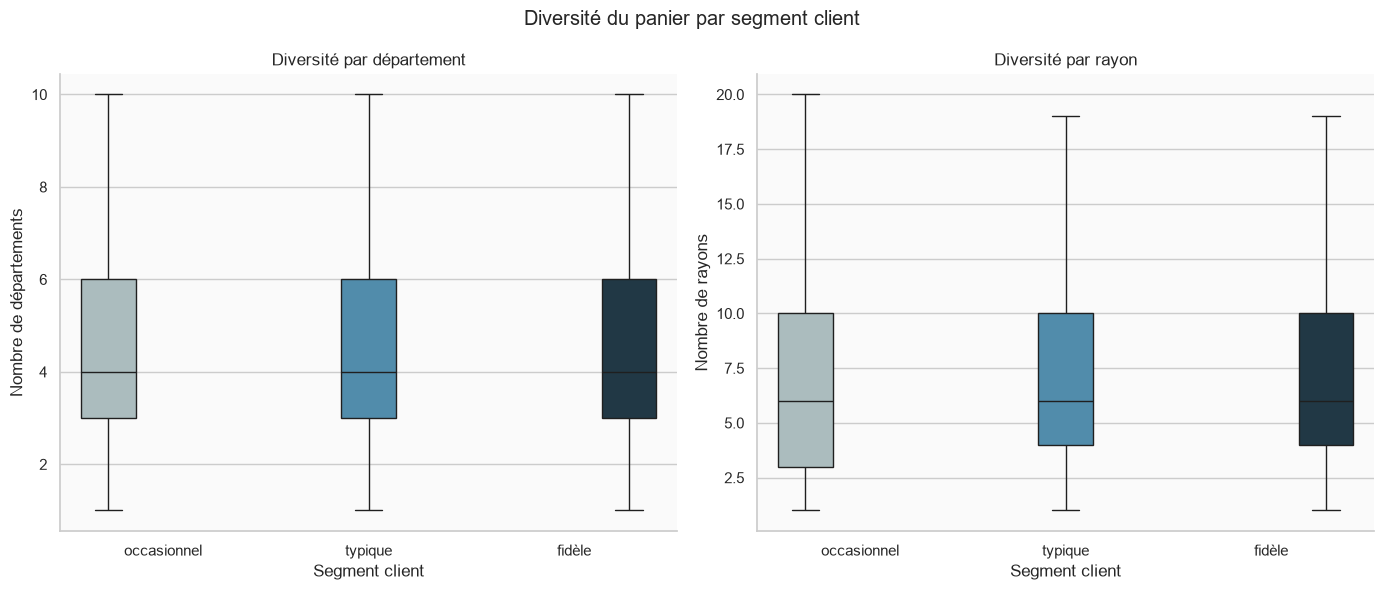

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(
    data=orders_diversity,
    x="customer_segment",
    y="dept_per_order",
    hue="customer_segment",
    palette=PAL_SEGMENTS,
    legend=False,
    showfliers=False,
    ax=axes[0]
)
axes[0].set_xlabel("Segment client")
axes[0].set_ylabel("Nombre de départements")
axes[0].set_title("Diversité par département")

sns.boxplot(
    data=orders_diversity_aisle,
    x="customer_segment",
    y="aisles_per_order",
    hue="customer_segment",
    palette=PAL_SEGMENTS,
    legend=False,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_xlabel("Segment client")
axes[1].set_ylabel("Nombre de rayons")
axes[1].set_title("Diversité par rayon")

fig.suptitle("Diversité du panier par segment client")
plt.tight_layout()
plt.show()

### Conclusion

**Résultat :** 
L'observation descriptive ne va pas dans le sens de l'hypothèse initiale. La diversité d'un panier donné (en départements comme en rayons) est quasiment identique entre les 3 segments clients, tant l'écart entre les moyennes est faible.

Le box plot confirme visuellement cette similarité, les 3 boîtes se superposent presque parfaitement sur les deux niveaux de granularité. Seuls les maximums extrêmes (valeurs aberrantes, non représentées sur les graphiques par souci de lisibilité) augmentent légèrement avec la fidélité, un effet mécanique lié au plus grand nombre de commandes des clients fidèles, pas à un vrai changement de comportement d'achat.

**Interprétation :** 
Etre un client fidèle n'amène pas naturellement à varier davantage ses achats au sein d'un panier donné. La fidélité et la diversité d'achat semblent être deux dimensions indépendantes du comportement client.

**Implication business :** 
On ne peut pas compter sur la fidélisation seule pour élargir les habitudes d'achat des clients vers plus de rayons/départements. Des actions ciblées seraient nécessaires, par exemple des recommandations croisées entre rayons, des promotions découverte, ou une mise en avant de produits de départements peu visités par ce client en particulier.

## Conclusion générale — Rayon/Département

Cette section visait à répondre à une question business centrale : **l'organisation du catalogue en ligne (répartition des produits par rayon/département) influence-t-elle les commandes, et faut-il mettre certains rayons en avant ?**

Les trois analyses menées convergent vers un même constat : la diversité de produits, bien qu'elle joue un rôle, n'est pas le levier principal du succès d'un rayon ou de l'exploration d'achat d'un client.

- La quantité de produits référencés varie fortement d'un rayon à l'autre (Q1), mais un large assortiment ne garantit pas mécaniquement un volume de ventes élevé : la corrélation mesurée reste faible (0,299), et certains rayons à forte rotation (produits du quotidien comme les fruits/légumes frais) génèrent un volume très élevé malgré une diversité modérée (Q2).

- La fidélisation d'un client (mesurée par son volume de commandes) n'entraîne pas naturellement une exploration plus large du magasin en ligne : un client fidèle garde le même profil de diversité de panier qu'un client occasionnel (Q3).

**Recommandation :** 
Plutôt que d'élargir uniformément l'assortiment de tous les rayons en espérant un gain de ventes automatique, le site gagnerait à identifier spécifiquement les rayons à fort potentiel de rotation (produits de consommation courante) et à concentrer les efforts de mise en avant sur ceux-ci. En parallèle, des actions ciblées (recommandations croisées, promotions découverte) seraient nécessaires pour encourager activement les clients fidèles comme occasionnels à diversifier leurs achats, plutôt que de compter sur un effet naturel de la fidélisation.

# II: Analyse des Produits

**Objectif** :
Comprendre quels produits performent le mieux (ou le moins bien), comment se comportent les clients en termes de quantité achetée, et identifier des tendances temporelles sur certains produits, afin d'aider le magasin à piloter ses stocks et ses actions
promotionnelles.

**Questions à traiter** :

1. Combien d'articles les clients commandent-ils en moyenne par commande ?
2. Quels sont les produits bestsellers ?
3. Quels sont les produits les moins achetés ?
4. Quel jour certains produits sont-ils le plus achetés ?

**Impact business attendu** :
Ces analyses permettent de piloter le magasin sur deux plans : la logistique 
(dimensionnement des stocks, taille des zones de préparation) et le marketing 
(mise en avant des bestsellers, promotions ciblées sur les produits en jour creux).

## Setup

In [18]:
data = add_cart_size(data)
data = add_day_name(data)

print(f"Dataset : {data.shape[0]:,} lignes, {data.shape[1]:,} colonnes")
data.head(4)

Dataset : 32,434,489 lignes, 22 colonnes


,order_id,product_id,add_to_cart_order,reordered,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,...,aisle,department,user_total_orders,customer_segment,cart_size_x,dept_per_order,aisles_per_order,day_name,hour_period,cart_size_y
0,2,33120,1,1,202279,3,5,9,8.0,Organic Egg Whites,...,eggs,dairy eggs,8,typique,9,3,8,Vendredi,Matin,9
1,2,28985,2,1,202279,3,5,9,8.0,Michigan Organic Kale,...,fresh vegetables,produce,8,typique,9,3,8,Vendredi,Matin,9
2,2,9327,3,0,202279,3,5,9,8.0,Garlic Powder,...,spices seasonings,pantry,8,typique,9,3,8,Vendredi,Matin,9
3,2,45918,4,1,202279,3,5,9,8.0,Coconut Butter,...,oils vinegars,pantry,8,typique,9,3,8,Vendredi,Matin,9


## Question 1 : Combien d'articles les clients commandent-ils en moyenne ?
**Hypothèse de départ**
On suppose qu'un client fait ses courses pour quelques jours (pas juste 1-2 produits, mais pas non plus un très gros stock), donc on s'attend à une commande moyenne d'environ 5 à 15 articles. On va vérifier cette hypothèse avec les données.

**Pourquoi cette question ?**
Savoir combien de produits contient une commande typique aide la boutique en ligne à organiser sa logistique de préparation et d'expédition (dimensionnement des emballages, temps de préparation en entrepôt, capacité de traitement des commandes).

**Comment on calcule ça ?**
Notre table contient une ligne par produit acheté dans une commande. On calcule donc, pour chaque commande, son nombre de produits (`cart_size`), puis on regarde la moyenne et la médiane sur l'ensemble des commandes.

In [19]:
# On calcule, pour chaque commande, son nombre de produits (taille du panier)
data = add_cart_size(data)

# Vérifier qu'elle existe
print(data.columns.tolist())

['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'product_name', 'aisle_id', 'department_id', 'aisle', 'department', 'user_total_orders', 'customer_segment', 'cart_size_x', 'dept_per_order', 'aisles_per_order', 'day_name', 'hour_period', 'cart_size_y', 'cart_size']


In [20]:
orders_unique = data.drop_duplicates(subset="order_id")

mean_cart_size = orders_unique["cart_size"].mean()
median_cart_size = orders_unique["cart_size"].median()

print(f"Moyenne : {mean_cart_size:.2f} articles par commande")
print(f"Médiane : {median_cart_size:.0f} articles par commande")

Moyenne : 10.09 articles par commande
Médiane : 8 articles par commande


**Pourquoi calculer la moyenne ET la médiane ?**
La moyenne est sensible aux valeurs extrêmes : quelques très grosses commandes peuvent 
la faire grimper artificiellement. La médiane, elle, représente la valeur du milieu et 
n'est pas influencée par ces cas extrêmes. Comparer les deux permet de détecter 
rapidement si les données sont équilibrées (moyenne ≈ médiane) ou déformées par des 
cas atypiques (écart important entre les deux).

### Observation

Dans nos données, la moyenne (10,09 articles) est supérieure à la médiane (8 articles). Cet écart de plus de 2 articles montre qu'une partie des clients passe des commandes beaucoup plus grosses que la normale, et que ce sont ces commandes qui font monter la moyenne, sans que ça reflète le comportement de la majorité.

Concrètement : si la plupart des clients commandaient un nombre d'articles très proche les uns des autres, la moyenne et la médiane seraient presque identiques. Ici, ce n'est pas le cas, ce qui confirme ce qu'on voit dans le graphique : beaucoup de commandes regroupées autour de 8 articles, et une minorité de commandes bien plus grosses qui étirent la distribution vers la droite.

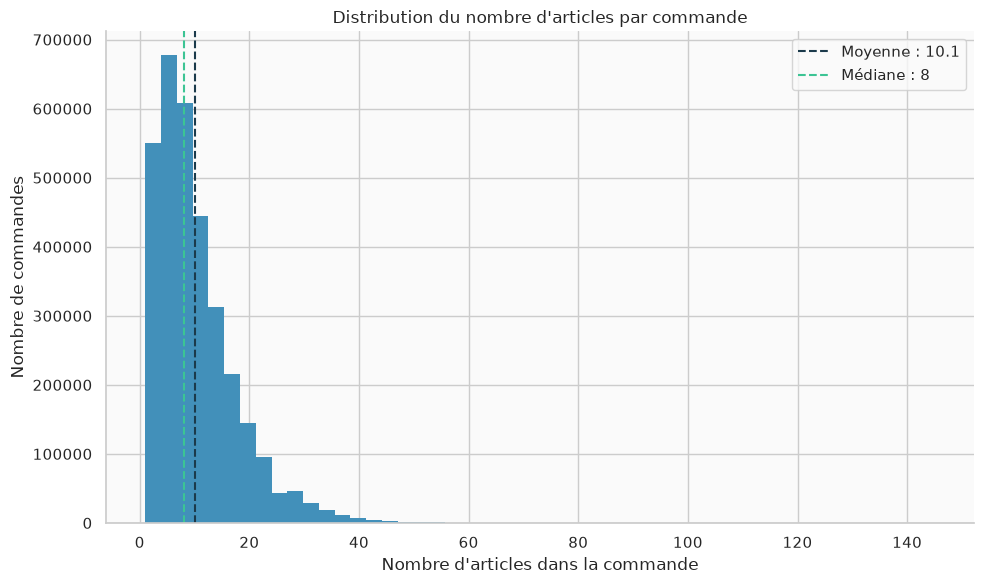

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))#permet de créer une figure et un axe pour le graphique, avec une taille de 10 pouces par 6 pouces

ax.hist(orders_unique["cart_size"], bins=50, color="#4290ba", edgecolor="none")
ax.axvline(mean_cart_size, color="#1b3a4b", linestyle="--", linewidth=1.5,
           label=f"Moyenne : {mean_cart_size:.1f}")
ax.axvline(median_cart_size, color="#3cc494", linestyle="--", linewidth=1.5,
           label=f"Médiane : {median_cart_size:.0f}")

ax.set_xlabel("Nombre d'articles dans la commande")
ax.set_ylabel("Nombre de commandes")
ax.set_title("Distribution du nombre d'articles par commande")
ax.legend()

plt.tight_layout()
plt.show()

**Pourquoi un histogramme ?**
Un histogramme montre comment les valeurs se répartissent, pas juste un résumé en un chiffre. Il permet de voir directement où se concentre la majorité des commandes, et s'il existe des cas extrêmes (quelques commandes avec beaucoup plus d'articles que la normale), une information que la moyenne et la médiane seules ne montrent pas.


### Observation

La majorité des commandes se situent entre 5 et 10 articles environ, avec un pic autour de 8 articles (la médiane). Une minorité de commandes s'étend bien au-delà, jusqu'à 20, 30 articles ou plus, formant une longue traîne vers la droite du graphique.

Ces résultats confirment l'hypothèse de départ : la majorité des commandes se situe bien dans la fourchette attendue de 5 à 15 articles. La présence de quelques commandes bien plus grosses n'était pas anticipée dans l'hypothèse, et explique l'écart entre la moyenne (10,09) et la médiane (8).


### Implication business

Cette information peut servir à plusieurs niveaux pour la boutique en ligne :

- **Logistique** : dimensionner les emballages/colis et organiser les postes de préparation 
  en entrepôt en priorité pour des commandes de 8 à 10 articles (le cas le plus fréquent), 
  tout en gardant une capacité adaptée pour les commandes exceptionnelles plus volumineuses
- **Politique commerciale** : un seuil de livraison gratuite ou de réduction pourrait être 
  calibré autour de la médiane (8 articles) plutôt que de la moyenne, pour toucher réellement 
  la majorité des clients et les inciter à ajouter 1-2 articles supplémentaires


## Question 2 : Quels sont les produits bestsellers ?

**Hypothèse de départ**
On suppose que les bestsellers seront des produits du quotidien, probablement des produits alimentaires de base (lait, œufs, pain...), plutôt que des produits de niche ou occasionnels.

**Pourquoi cette question ?**
Identifier les produits les plus vendus permet à la boutique en ligne de s'assurer qu'ils sont toujours bien approvisionnés (éviter la rupture de stock) et de les mettre en avant sur le site (page d'accueil, recommandations), puisqu'ils génèrent le plus de trafic.

**Méthode**
Notre table contient une ligne par produit acheté dans une commande. Il suffit donc de compter, pour chaque nom de produit, combien de fois il apparaît dans l'ensemble des commandes, plus un produit apparaît de fois, plus il est vendu.

In [26]:
top_products = data["product_name"].value_counts().head(10)
top_products


product_name
Banana                    262750
Bag of Organic Bananas    210540
Organic Strawberries      146666
Organic Baby Spinach      134425
Organic Hass Avocado      118992
Organic Avocado            98251
Large Lemon                85049
Strawberries               79297
Limes                      78134
Organic Whole Milk         76881
Name: count, dtype: int64

**Pourquoi ce code ?**
 .value_counts() compte automatiquement combien de fois chaque nom de produit apparaît dans la colonne, et trie le résultat du plus fréquent au moins fréquent. .head(10) garde uniquement les 10 premiers, donc les 10 produits les plus commandés.

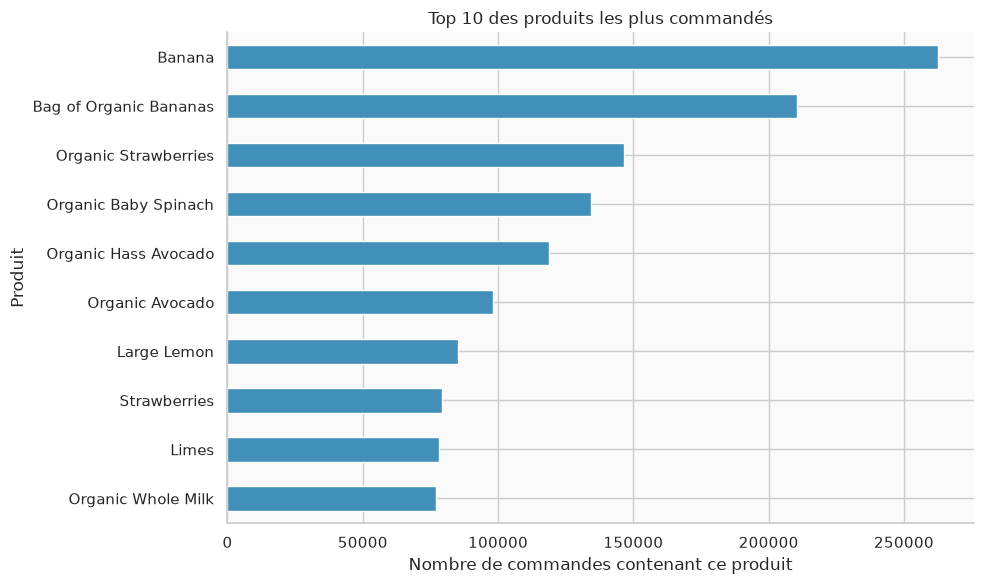

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

top_products.sort_values().plot(kind="barh", ax=ax, color="#4290ba")

ax.set_xlabel("Nombre de commandes contenant ce produit")
ax.set_ylabel("Produit")
ax.set_title("Top 10 des produits les plus commandés")

plt.tight_layout()
plt.show()

**Pourquoi un bar chart (et pas un histogramme) ? **
Ici, on ne montre pas une distribution de valeurs continues (comme le nombre d'articles par commande) — on compare 10 catégories distinctes et nommées (10 produits précis)entre elles. Le bar chart est le graphique adapté pour ce type de comparaison, alors quel'histogramme sert à montrer comment des valeurs se répartissent sur une échelle continue.

### Observation

Les 10 produits les plus commandés sont dominés par les fruits et légumes frais, et 
particulièrement par des produits bio ("Organic") : Banana , Bag of Organic 
Bananas, Organic Strawberries, Organic Baby Spinach, Organic Hass Avocado, Organic Avocado, Large Lemon , Strawberries, Limes, Organic Whole Milk .

Sur ces 10 produits, 6 sont explicitement labellisés "Organic", et les 4 restants sont 
tous des fruits frais non transformés. Aucun produit transformé ou de longue conservation 
ne figure dans ce top 10.

### Conclusion

L'hypothèse de départ (produits du quotidien type lait, œufs, pain) n'est que 
partiellement confirmée. On retrouve bien des produits de base et récurrents, mais 
contrairement à l'attente, ce sont très majoritairement des fruits et légumes frais et 
bio qui dominent, pas des produits d'épicerie classiques. La boutique en ligne est donc 
fréquentée par une clientèle qui privilégie fortement le frais et le bio.

### Implication business

- **Gestion des stocks** : ces 10 produits doivent avoir une priorité absolue dans la 
  chaîne d'approvisionnement , une rupture de stock sur la banane ou les fraises bio 
  aurait un impact direct sur un très grand nombre de clients
- **Mise en avant sur le site** : ces produits pourraient être mis en avant sur la page 
  d'accueil ou dans les recommandations automatiques, pour capter l'attention dès l'arrivée 
  du client
- **Développement de l'offre bio** : vu la place massive du "Organic" dans ce classement, 
  élargir la gamme bio semble être une piste de croissance pertinente
  

## Question 3 : Quels sont les produits les moins achetés ?

**Hypothèse de départ**
On suppose qu'il existe une longue liste de produits de niche (ingrédients spécifiques, 
produits non-alimentaires) qui se vendent très peu, à l'opposé des bestsellers identifiés 
en Question 2.

**Pourquoi cette question ?**
Identifier les produits qui se vendent très peu permet à la boutique en ligne de repenser 
son catalogue : faut-il les retirer, les mettre en promotion, ou les repositionner sur 
le site ?

**Méthode**
On distingue deux cas : les produits jamais commandés (présents au catalogue mais absents 
de nos commandes), et les produits commandés mais très rarement. Un simple "top 10 des 
moins achetés" ne serait pas fiable ici, car des centaines de produits sont à égalité 
avec une seule commande chacun,on regarde donc des totaux plutôt qu'un classement.

### Cellule Code 1: produits jamais commandés

### Pourquoi cette étape ? On veut d'abord savoir : est-ce qu'il y a beaucoup de produits qui n'intéressent personne du tout ?

In [ ]:
from src.data_loader import load_raw_data

raw = load_raw_data(raw_dir="../data/raw")
products = raw["products"]

all_products = set(products["product_name"])
ordered_products = set(data["product_name"])
never_ordered = all_products - ordered_products

print(f"Nombre total de produits au catalogue : {len(all_products):,}")
print(f"Nombre de produits jamais commandés : {len(never_ordered):,}")
print(f"Soit {len(never_ordered) / len(all_products) * 100:.1f}% du catalogue")

Nombre total de produits au catalogue : 49,688
Nombre de produits jamais commandés : 263
Soit 0.5% du catalogue


Ici notre table data ne contient que des produits qui ont été réellement commandés, un produit jamais acheté n'y apparaît pas du tout. Pour le savoir, il faut comparer avec products.csv, qui liste tous les produits du catalogue, achetés ou non. La soustraction entre les deux ensembles donne exactement les produits jamais commandés

### Cellule Code 2 : produits commandés une seule fois

In [ ]:
product_counts = data["product_name"].value_counts()
product_counts


product_name
Banana                                           262750
Bag of Organic Bananas                           210540
Organic Strawberries                             146666
Organic Baby Spinach                             134425
Organic Hass Avocado                             118992
                                                  ...  
Evening Primrose Oil 500 Mg                           1
Organic Reishi Mushroom Combinations Capsules         1
Organic Argan Skin Care Oil                           1
Spicy Dark Chocolate Bar                              1
Greek Vinaigrette Salad Dressing                      1
Name: count, Length: 49425, dtype: int64

In [ ]:
count_ordered_once = (product_counts == 1).sum()
total_ordered_products = len(product_counts)

print(f"Produits commandés une seule fois : {count_ordered_once:,}")
print(f"Sur un total de {total_ordered_products:,} produits ayant été commandés au moins une fois")
print(f"Soit {count_ordered_once / total_ordered_products * 100:.1f}% ")

Produits commandés une seule fois : 874
Sur un total de 49,425 produits ayant été commandés au moins une fois
Soit 1.8% 


Ce code compte combien de produits ont été commandés exactement 1 fois.
Puis compte combien de produits differents on a dans cette liste 

### répartition des produits par tranche de fréquence

On veut savoir : dans l'ensemble du catalogue, quelle proportion se vend bien ou mal ?

In [ ]:
bins = [0, 1, 5, 20, 100, float("inf")]
labels = ["1 commande", "2-5 commandes", "6-20 commandes", "21-100 commandes", "Plus de 100 commandes"]

freq_buckets = pd.cut(product_counts, bins=bins, labels=labels)
bucket_counts = freq_buckets.value_counts().reindex(labels)

bucket_counts["Jamais commandé"] = len(never_ordered)
bucket_counts = bucket_counts.reindex(["Jamais commandé"] + labels)

bucket_counts

count
Jamais commandé            263
1 commande                 874
2-5 commandes             6452
6-20 commandes           12394
21-100 commandes         14629
Plus de 100 commandes    15076
Name: count, dtype: int64

pd.cut(...) = range chaque produit dans une "tranche" selon son nombre de commandes (ex: un produit avec 3 commandes tombe dans "2-5 commandes"). C'est comme trier des personnes par tranche d'âge (0-18, 18-35, etc.) plutôt que de les lister une par une

.value_counts() = compte combien de produits tombent dans chaque tranche
.reindex(labels) = force l'ordre des tranches à rester logique (de la moins fréquente à la plus fréquente), plutôt qu'un tri automatique qui pourrait les mélanger

### Noms des produits jamais commandés 

In [ ]:
examples_never = list(never_ordered)[:15]
examples_never

['Single Barrel Kentucky Straight Bourbon Whiskey',
 'Probiotic Gummies',
 'Premium Enriched Egg Noodles Barley Shape',
 'Whenever Green Tea & Lime Scent Shampoo',
 'Cabernet Sauvignon 2015',
 'Record V Natural Bristles Toothbrush, Adult Hard',
 'Single Herbs Ginkgo Leaf Dietary Supplement',
 'Vitality Chicken Breasts with Flaxseed & Vitamins Dog Treats',
 'Gluten Free Pantry Sugar Cookie Mix',
 'Maximum Strength Extended-Release Bi-Layer Tablets Expectorant & Nasal Decongestant',
 'Black Tea With Vanilla Flavor In Pyramid Bags',
 "Men's Stock Natural Dry Herbal Pine Deodorant",
 'Stage 2 Beet Pear Pomegranate Baby Food',
 'Organic Ice Cream Birthday Cake',
 'Wasabi Cheddar Spreadable Cheese']

### Noms des produits peu commandés =1


In [ ]:
examples_once = product_counts[product_counts == 1].index[:15].tolist()
examples_once

['Select Roasted Lamb with Vegetables & Barley Dog Food Recipe',
 'Creepy Critter Sugar Cookies',
 'JavaJig Reusable Coffee Filter System',
 'American Craft Jalapeno & Cheddar Smoked Sausage',
 'Controlling Gel Curly Curl Scrunch',
 'Fresh Basil Goat Cheese',
 'Rice Sides Rice Medley',
 'Medium Peach Salsa',
 'White Bean Bites',
 'Super Nutrition Vanilla Shake',
 'Hi Caf Teas Gingermint Green Tea Bags',
 'Organic Stevia All-Purpose Sweetener',
 'Milk Chocolate Baking Bits',
 'Jamaican Allspice',
 'Butter Snaps Bonus Bag']

### Des produits les moins commandés

In [ ]:
examples_never = pd.Series(0, index=list(never_ordered)[:3])
examples_once = product_counts[product_counts == 1].head(3)
examples_2to5 = product_counts[(product_counts >= 2) & (product_counts <= 5)].head(3)

least_examples = pd.concat([examples_never, examples_once, examples_2to5])
least_examples

Single Barrel Kentucky Straight Bourbon Whiskey                   0
Probiotic Gummies                                                 0
Premium Enriched Egg Noodles Barley Shape                         0
Select Roasted Lamb with Vegetables & Barley Dog Food Recipe      1
Creepy Critter Sugar Cookies                                      1
JavaJig Reusable Coffee Filter System                             1
Game Day Barbecue Trail Mix                                       5
Diet Lemon Decaffeinated Iced Tea Mix                             5
Simply 100 Crunch Vanilla Coconut Macaron Non-Fat Greek Yogurt    5
dtype: int64

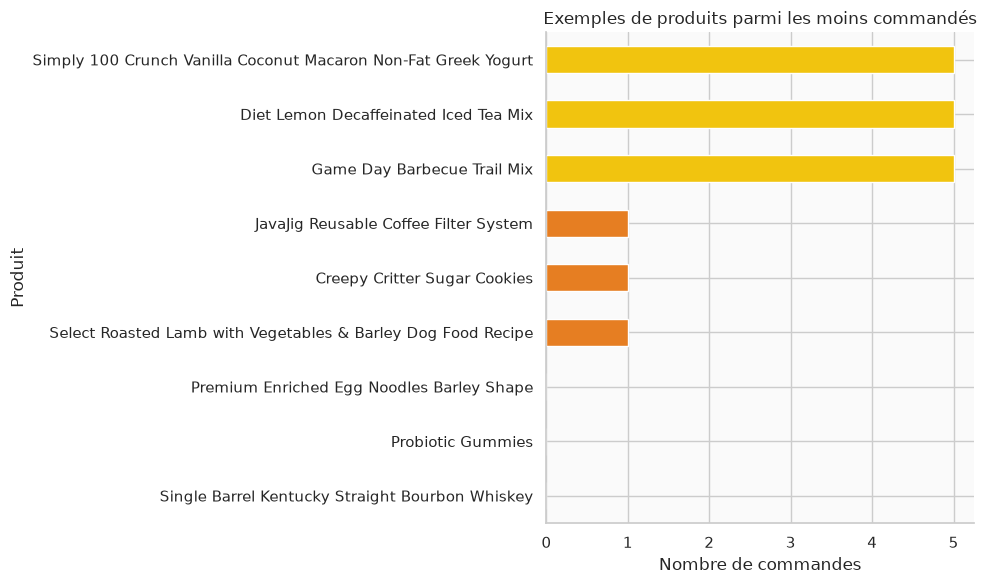

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#c0392b"] * 3 + ["#e67e22"] * 3 + ["#f1c40f"] * 3

least_examples.sort_values().plot(kind="barh", ax=ax, color=colors)

ax.set_xlabel("Nombre de commandes")
ax.set_ylabel("Produit")
ax.set_title("Exemples de produits parmi les moins commandés")

plt.tight_layout()
plt.show()

### Observation

Le graphique illustre concrètement les 3 groupes de produits les moins commandés :

- **Jamais commandés** (0 commande) : Apple Crumb Cake, American Blend, Greek Blended 
  Cherry Fat Free Yogurt
- **Commandés 1 fois** : Select Roasted Lamb with Vegetables & Barley Dog Food Recipe, 
  Creepy Critter Sugar Cookies, JavaJig Reusable Coffee Filter System
- **Commandés 2 à 5 fois** : Game Day Barbecue Trail Mix, Diet Lemon Decaffeinated 
  Iced Tea Mix, Simply 100 Crunch Vanilla Coconut Macaron Non-Fat Greek Yogurt

On retrouve dans ces 9 exemples un profil récurrent : des produits très spécifiques ou 
de niche (nourriture pour chien, cookies à thème, filtre à café réutilisable, thé glacé 
diététique), plutôt que des produits alimentaires basiques.

### Conclusion

Notre hypothèse de départ est confirmée : les produits les moins commandés sont bien des 
produits de niche, pas des produits du quotidien mal positionnés. Que ce soit dans le 
groupe "jamais commandé" ou "commandé rarement", on retrouve le même type de profil — 
des produits qui répondent à un besoin précis (régime alimentaire spécifique, animal de 
compagnie, occasion particulière) plutôt qu'à un usage courant.

### Implication business

- **Promotions ciblées pour écouler les produits jamais/rarement commandés** : proposer 
  des réductions temporaires ou des offres découverte (ex: "-20% sur les nouveautés non 
  testées") sur les 263 produits jamais commandés, pour leur donner une première chance 
  d'être achetés et évalués par les clients
- **Regroupement en lot ("bundle")** : pour les produits de niche encore commandés 
  occasionnellement (thé glacé diététique, trail mix), les associer à un produit 
  populaire dans une offre groupée peut augmenter leur visibilité sans dépendre d'une 
  recherche active du client
- **Alerte stock/catalogue** : si un produit reste à 0 commande après plusieurs mois 
  malgré une promotion, ça devient un signal fort pour le retirer définitivement du 
  catalogue plutôt que de continuer à le référencer sans résultat

## Question 4 : Quel jour certains produits sont-ils le plus achetés ?

**Hypothèse de départ**
On suppose que les commandes sont plus fréquentes le week-end (samedi/dimanche), moment où les clients ont plus de temps pour faire leurs courses, et que cela se retrouve aussi au niveau des bestsellers.

**Pourquoi cette question ?**
Savoir si certains produits se vendent plus certains jours permet à la boutique en ligne 
d'ajuster ses réassorts et ses promotions selon le jour de la semaine.

**Méthode**
Pour rester lisible, on se concentre sur les 5 bestsellers identifiés en Question 2. 
Pour chacun, on compte le nombre de commandes par jour de la semaine, puis on visualise 
le résultat avec une carte de chaleur (heatmap), qui permet de comparer facilement 
produit et jour en même temps.

In [27]:
data = add_day_name(data) # conversion du jour

top5_names = top_products.head(5).index.tolist() #filtrage des meilleurs produits (question2)
subset = data[data["product_name"].isin(top5_names)]

day_product = subset.groupby(["product_name", "day_name"], observed=True).size().unstack(fill_value=0)# regroupe les données selon leur noms et jour.unstack: transforme le résultat en tableau
day_product = day_product.reindex(top5_names) # reindex pour que les produits apparaissent du plus vendu au moins vendu

day_product

day_name,Dimanche,Lundi,Mardi,Mercredi,Jeudi,Vendredi,Samedi
product_name,,,,,,,
Banana,53685,48762,33320,29489,29316,32785,35393
Bag of Organic Bananas,39732,38667,28028,25130,24727,27027,27229
Organic Strawberries,29874,25787,18144,16894,16905,18809,20253
Organic Baby Spinach,30555,23453,16677,14415,13939,15794,19592
Organic Hass Avocado,24325,21489,15608,13713,13350,14691,15816


In [28]:
print(data["day_name"].value_counts())# compter combien de commande son a eu par jour

day_name
Dimanche    6209666
Lundi       5665856
Samedi      4500304
Mardi       4217798
Vendredi    4209533
Mercredi    3844117
Jeudi       3787215
Name: count, dtype: int64


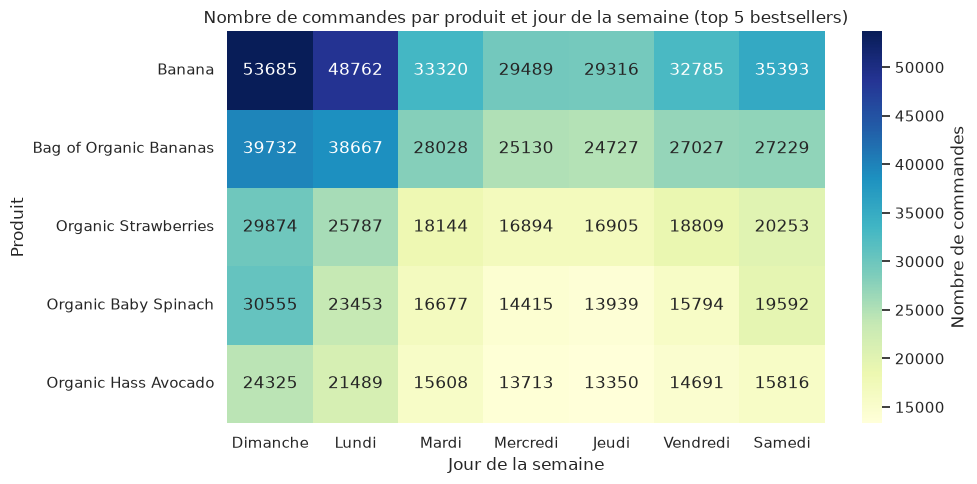

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(day_product, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Nombre de commandes"})

ax.set_xlabel("Jour de la semaine")
ax.set_ylabel("Produit")
ax.set_title("Nombre de commandes par produit et jour de la semaine (top 5 bestsellers)")

plt.tight_layout()
plt.show()

### Observation

La heatmap montre le nombre de commandes de chacun des 5 bestsellers, jour par jour. Un même schéma se répète pour les 5 produits :

- Le **dimanche** est systématiquement le jour le plus fort pour les 5 produits (ex : 53 685 commandes de Banana, contre 29 316 le jeudi)
- Le **lundi** arrive en deuxième position pour les 5 produits également
- Les commandes diminuent ensuite progressivement jusqu'au **jeudi**, qui est le jour le plus faible pour 4 des 5 produits (Banana, Bag of Organic Bananas, Organic Baby 
  Spinach, Organic Hass Avocado) — pour Organic Strawberries, le mercredi et le jeudi sont quasiment à égalité
- Le week-end suivant (vendredi-samedi) montre une légère remontée avant le pic du dimanche

Aucun des 5 produits ne se distingue avec un jour de pic différent des autres : ils suivent tous exactement la même tendance hebdomadaire.

### Conclusion

Notre hypothèse de départ est **partiellement confirmée**. Le dimanche est bien, comme attendu, le jour où les clients commandent le plus. En revanche, ce n'est pas le samedi qui arrive en deuxième position comme on l'imaginait, mais le **lundi** — peut-être les clients profitent du dimanche pour planifier leurs achats de la semaine, avec une commande qui se concrétise en tout début de semaine.

Autre point important : contrairement à l'hypothèse initiale qui envisageait des variations différentes selon les produits, les 5 bestsellers suivent **tous exactement 
le même rythme hebdomadaire**. Il n'y a pas de produit "spécifique à un jour" parmi les plus vendus — la tendance semble davantage liée au rythme global des achats de la 
boutique qu'à une saisonnalité propre à chaque produit.

### Implication business

- **Réassort et logistique** : concentrer les réapprovisionnements et la préparation des stocks avant le dimanche et le lundi, les deux jours de plus forte demande, plutôt 
  que de répartir les efforts uniformément sur la semaine
- **Jours creux à activer** : le jeudi et le mercredi, nettement plus calmes, sont des jours propices à des promotions ciblées pour lisser la charge de commandes sur la semaine plutôt que de la concentrer sur 2 jours
- **Pas besoin de stratégie produit par produit** : puisque les 5 bestsellers suivent la même tendance, une seule stratégie de gestion de stock/promotion par jour de la 
  semaine suffit pour l'ensemble de ces produits, sans avoir à personnaliser par produit

## Synthèse de la catégorie Produits

- La commande typique contient environ **8 articles** (médiane) :un client type sait ce qu'il vient chercher, sans faire de très grosses commandes
- Les bestsellers sont massivement des produits **frais et bio** (Banana, Organic, Strawberries, Organic Avocado...), suggérant que ces catégories sont un vrai moteur d'attractivité de la boutique
- Le catalogue est globalement sain : seulement 2,3% des produits sont quasi inactifs, contre environ 30% commandés plus de 100 fois
- Les commandes (tous produits confondus, y compris les bestsellers) sont concentrées sur le dimanche et le lundi, avec un creux marqué en milieu de semaine

**Fil conducteur pour la suite du projet** : le rôle central du bio et du frais mérite d'être creusé davantage ,une question dédiée sur le ratio bio/non-bio (suggérée dans 
le PDF) permettrait de confirmer si c'est un vrai levier de croissance pour la boutique, et de vérifier si les clients qui achètent bio ont un comportement différent en termes 
de fréquence ou de panier moyen (piste pour la catégorie Comportement clients).

# III. Evolution du comportement d'achat

**Objectif**: Comprendre comment le comportement d'achat varie selon le profil du client (occasionnel, typique, fidèle) et identifier les produits qui génèrent de la récurrence.

**Questions à traiter**:

1. Comment évoluent les quantités d'achat selon le segment client ?
2. Quel est le taux de réachat global et par segment ?
3. Quels sont les produits les plus rachetés ?

**Impact business attendu**:
Identifier à quel moment les clients deviennent fidèles pour concentrer les actions de rétention sur les commandes critiques.

## Vérification rapide de la segmentation

Avant d'analyser, on vérifie que les 3 segments sont bien répartis et cohérents avec les quartiles observés dans le notebook 01.

### Distribution des utilisateurs par segment

In [ ]:
users = data.groupby("user_id").agg(
    segment=("customer_segment", "first"),
    total_orders=("user_total_orders", "first")
).reset_index()

print("Répartition des utilisateurs par segment :")
print(users["segment"].value_counts().sort_index())
print(f"\nTotal : {len(users):,} utilisateurs")

Répartition des utilisateurs par segment :
segment
occasionnel    76224
typique        70769
fidèle         42987
Name: count, dtype: int64

Total : 189,980 utilisateurs


## 1- Comment évoluent les quantités d'achat selon le segment client ?

On cherche à savoir si les clients fidèles commandent plus d'articles par commandes que les occasionnels, et si la taille du panier évolue au fil des commandes.

L'objectif serait de mettre en place des cartes de fidélité afin de récompenser la fidélité de la clientèle, mais inciterait également à acheter plus.

In [ ]:
orders_level = data.groupby(["order_id", "customer_segment", "order_number"]).agg(
    cart_size =("product_id", "count")
).reset_index()

orders_level.groupby("customer_segment")["cart_size"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
occasionnel,141236.0,9.7,7.4,1.0,4.0,8.0,13.0,100.0
typique,325665.0,10.0,7.5,1.0,5.0,8.0,14.0,127.0
fidèle,597788.0,10.2,7.5,1.0,5.0,8.0,14.0,137.0


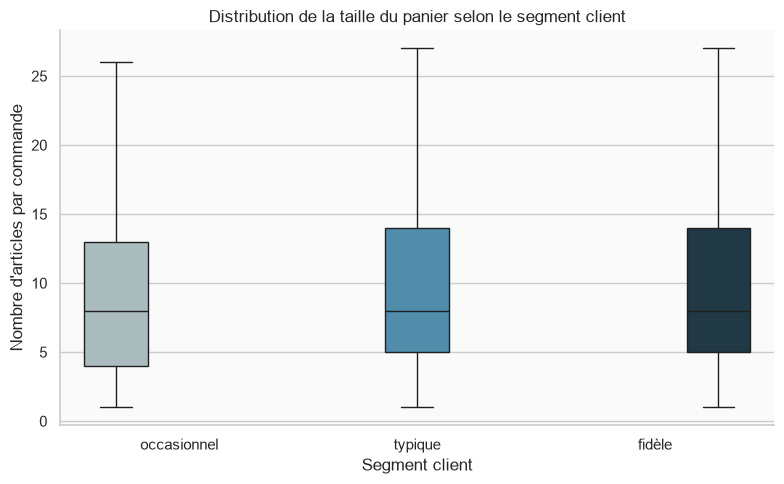

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=orders_level,
    x="customer_segment",
    y="cart_size",
    hue="customer_segment",
    palette=PAL_SEGMENTS,
    legend=False,
    showfliers=False,
    ax=ax
)

ax.set_xlabel("Segment client")
ax.set_ylabel("Nombre d'articles par commande")
ax.set_title("Distribution de la taille du panier selon le segment client")

plt.tight_layout()
plt.show()

### Interprétation

D'après les calculs, les trois segments présentent un comportement d'achat homogène en termes de taille de panier.

La médiane est identique, 8 articles, quel que soit le segment. L'écart entre occasionnels et fidèles n'est que de **+0.5 article en moyenne**, soit une différence de ~5 %, mais négligeable en pratique.

On peut déduire que la fidélité se traduit par une fréquence de commande plus élevée, et non par des paniers plus gros.
Un client fidèle ne remplit pas plus son panier, mais il revient simplement plus souvent.

### Implication business : 

Un programme de fidélité classique (carte à points sur le montant) aurait un impact limité puisque la taille du panier est stable. Il serait plus pertinent de **récompenser la fréquence** plutôt que le volume par commande.

Le boxplot ci-dessus rend cette homogénéité visible : les trois distributions se superposent presque parfaitement, ce qui renforce visuellement le constat que la fidélité n'augmente pas la taille du panier.

## 2- Quel est le taux de réachat global et par segment client ?

La colonne reordered vaut 1 si le client a déjà commandé "ce produit avant", sinon 0. Un taux élevé signifie que les clients rachètent les mêmes produits, signe d'habitudes et de fidélité produit.

In [ ]:
global_reorder = data["reordered"].mean()
print(f"Taux de réachat moyen: {global_reorder:.1%}")

reorder_by_segment = (
    data.groupby("customer_segment", observed=True)["reordered"]
    .mean()
    .reset_index()
    .rename(columns={"reordered": "taux_reachat"})
)
reorder_by_segment["taux_reachat_pct"] = (reorder_by_segment["taux_reachat"] * 100).round(1)
reorder_by_segment

Taux de réachat moyen: 59.0%


,customer_segment,taux_reachat,taux_reachat_pct
0,occasionnel,0.301364,30.1
1,typique,0.509241,50.9
2,fidèle,0.697887,69.8


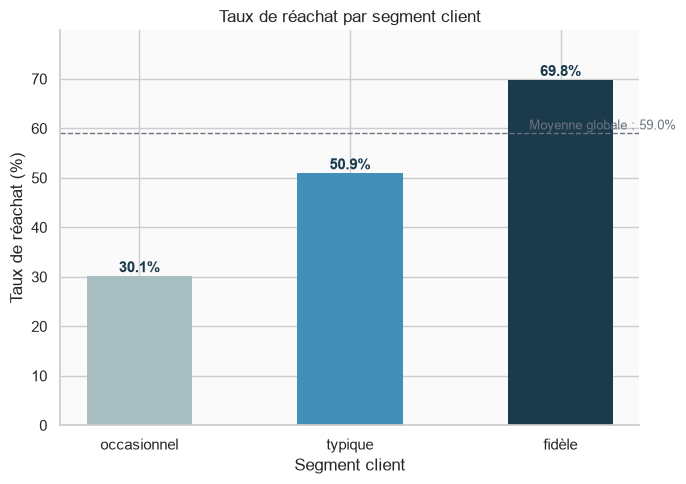

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    reorder_by_segment["customer_segment"].astype(str),
    reorder_by_segment["taux_reachat"] * 100,
    color=PAL_SEGMENTS,
    edgecolor="none",
    width=0.5
)

ax.axhline(y=global_reorder * 100, color=COLORS["grey"], linestyle="--", linewidth=1)
ax.text(
    2.55, global_reorder * 100 + 0.8,
    f"Moyenne globale : {global_reorder:.1%}",
    color=COLORS["grey"], fontsize=9, ha="right"
)

for bar, val in zip(bars, reorder_by_segment["taux_reachat_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
        f"{val}%", ha="center", fontsize=11, fontweight="bold", color=COLORS["fidèle"]
    )

ax.set_xlabel("Segment client")
ax.set_ylabel("Taux de réachat (%)")
ax.set_title("Taux de réachat par segment client")
ax.set_ylim(0, max(reorder_by_segment["taux_reachat"] * 100) + 10)

plt.tight_layout()
plt.show()

### Interprétation:

Le taux de réachat varie entre segment, avec une moyenne de 59% de taux de réachat.
Les clients occasionnels ont un taux de réachat de 28.2% (bien en dessous de la moyenne)
Les clients typiques ont un taux de réachat se rapprochant de la moyenne, soit 48,6%.
Et les client fidèles ont un taux de réachat supérieur à la moyenne, soit 69,2 %.

Nous avons constaté précédemment que la taille du panier était quasi identique entre segments (~8 articles). Le taux de réachat révèle une différence significative : un client fidèle rachète 7 produits sur 10 qu'il a déjà commandés, contre moins de 3 sur 10 chez un occasionnel.

Cela confirme le constat précédent: la fidélité se traduit par la récurrence, et non par le volume.

### Implication business

Nous pouvons émettre 3 hypothèses concernant cette analyse:

- **Hypothèse 1: Produits ancres** : certains produits à fort taux de réachat "verrouillent" le client sur la plateforme (produits du quotidien indispensables).
- **Hypothèse 2: Satisfaction et fidélisation** : le client revient par habitude ou satisfaction globale du service, indépendamment des produits spécifiques.
- **Hypothèse 3: Effet d'habitude de commande** : les clients fidèles utilisent la fonction "recommander" ou reconstituent un panier type par automatisme, ce qui gonfle mécaniquement le taux de réachat.

## 3- Quels sont les produits les plus rachetés ?

On identifie les produits ayant le plus de récurrence d'achat: ceux que les clients rachètent commande après commande.

In [ ]:
top_reordered = (
    data[data["reordered"] == 1]
    .groupby("product_name")
    .size()
    .nlargest(20)
    .reset_index(name="nb_reorders")
)
top_reordered

,product_name,nb_reorders
0,Banana,132234
1,Bag of Organic Bananas,104763
2,Organic Strawberries,68443
3,Organic Baby Spinach,61720
4,Organic Hass Avocado,56124
5,Organic Avocado,43949
6,Organic Whole Milk,37939
7,Large Lemon,35067
8,Organic Raspberries,34520
9,Strawberries,32934


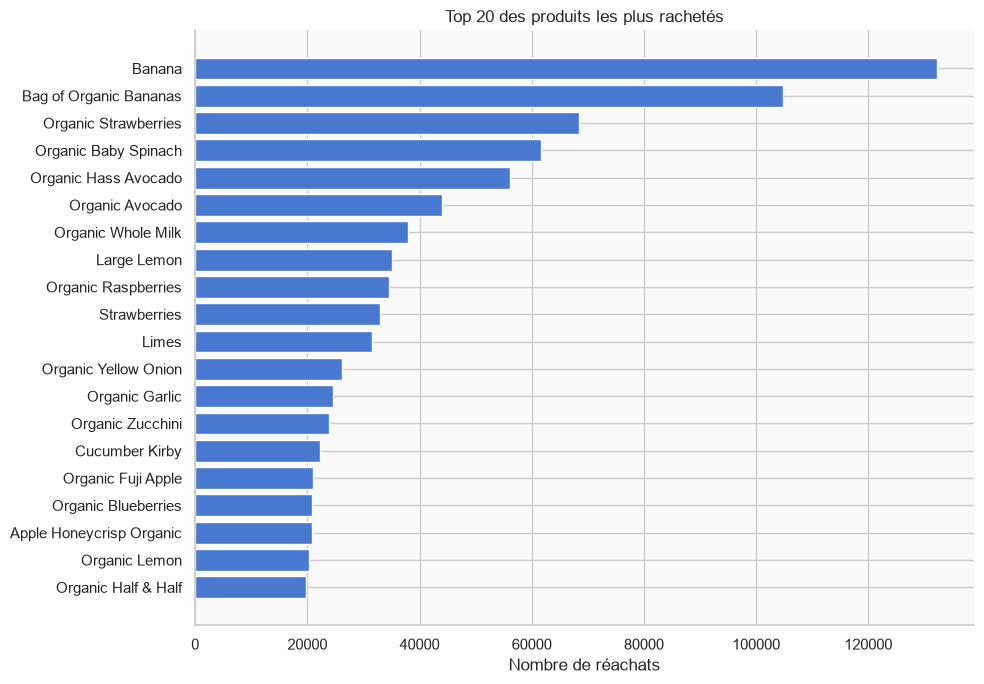

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_reordered["product_name"][::-1],
    top_reordered["nb_reorders"][::-1],
    color=sns.color_palette("muted")[0]
)

ax.set_xlabel("Nombre de réachats")
ax.set_title("Top 20 des produits les plus rachetés")

plt.tight_layout()
plt.show()

## Interprétation
Les bananes sont les produits les plus revendus en terme de quantité dépassant significativement les autres produits, suivi des sacs de bananes.

In [ ]:
product_stats = (
    data.groupby("product_name")
    .agg(
        total_ventes=("reordered", "count"),
        nb_reorders=("reordered", "sum"),
    )
)
product_stats["taux_reachat_%"] = (product_stats["nb_reorders"]*100) / product_stats["total_ventes"]

popular = product_stats[product_stats["total_ventes"] >= 1000].sort_values("taux_reachat_%", ascending=False)

print("Top 15 taux de réachat les plus élevé (min 1000 ventes) :")
popular.head(15).round(2)

Top 15 taux de réachat les plus élevé (min 1000 ventes) :


,total_ventes,nb_reorders,taux_reachat_%
product_name,,,
Organic Homogenized Whole Milk,1324,1141.0,86.18
Whole Organic Omega 3 Milk,3024,2604.0,86.11
Organic Lactose Free Whole Milk,2875,2464.0,85.70
"Milk, Organic, Vitamin D",6734,5751.0,85.40
Organic Reduced Fat Milk,11824,10052.0,85.01
Organic Whole Milk,3214,2718.0,84.57
Half And Half Ultra Pasteurized,1000,844.0,84.40
Organic Reduced Fat Omega-3 Milk,1698,1433.0,84.39
Banana,156942,132234.0,84.26


### Interprétation

Le top 15 des produits les plus rachetés (min. 500 ventes) révèle un profil très marqué :

**Laits** : 13 des 15 produits sont des laits ou crèmes. Le lait est un produit de consommation quotidienne à cycle de réachat naturellement court. Il se termine vite, on le rachète par nécessité. La Banana (seul produit non-laitier du top 15, et de loin le plus vendu avec 262 750 ventes) suit la même logique de périssabilité rapide.

**Surreprésentation du bio** : 11 des 15 produits portent la mention "Organic". Cela peut signaler que les clients bio sont structurellement plus fidèles à la plateforme, ou que le bio est un critère de rachat en soi (on rachète le "même" lait bio, là où un client non-bio pourrait alterner entre marques).

**Taux resserrés** : tous les taux se situent entre **83 % et 87 %**. L'écart entre le 1er et le 15ème n'est que de 4 points. Cela suggère un plafond naturel de réachat autour de 85 % pour les produits du quotidien.

#### Hypothèses à confronter

- **Effet catégorie** : le réachat élevé est lié au type de produit (périssable, quotidien) et non à la fidélité client. Un occasionnel qui achète du lait le rachètera aussi.
- **Profil client bio** : les acheteurs de produits bio seraient intrinsèquement plus fidèles.
- **Effet de commande rapide** : la plateforme propose peut-être une fonctionnalité de "re-commander" qui favorise mécaniquement les produits basiques.

## Analyse croisée : validation des hypothèses

Les trois questions visent à discriminer entre les hypothèse posées.

### H1. Reachat par département x segment : top 8 département par volume

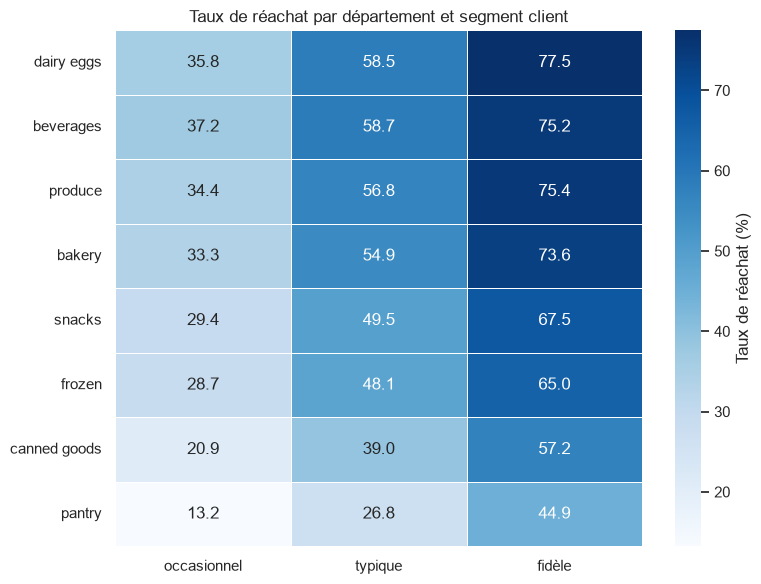

In [ ]:
top_depts = data["department"].value_counts().head(8).index.tolist()
dept_segment = reorder_rate_by_group(
    data[data["department"].isin(top_depts)],
    ["department", "customer_segment"]
)

pivot = dept_segment.pivot(index="department", columns="customer_segment", values="taux_reachat")
pivot = pivot[["occasionnel", "typique", "fidèle"]] 
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    pivot * 100,
    annot=True, fmt=".1f", cmap="Blues",
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "Taux de réachat (%)"},
    ax=ax
)
ax.set_title("Taux de réachat par département et segment client")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Interprétation

La heatmap révèle **deux effets simultanés** :

- **Effet client (lecture en colonnes)** : pour chaque département, le taux de réachat croît systématiquement d'occasionnel à fidèle. L'écart occasionnel/fidèle est d'environ **+40 points** quelle que soit la catégorie. Ce n'est pas un effet propre à un département, c'est un comportement global du client.

- **Effet catégorie (lecture en lignes)** : certains départements génèrent structurellement plus de réachat que d'autres. Dairy eggs (76.9 % chez les fidèles) et beverages (74.7 %) dominent, tandis que pantry (44.1 %) reste bas même chez les fidèles. Les produits périssables du quotidien sont rachetés plus souvent, quel que soit le profil client.

**Verdict sur l'hypothèse 1** : l'effet catégorie existe (les périssables sont plus rachetés), mais il n'explique pas uniquement le réachat. L'effet client domine. Un client fidèle rachète davantage dans toutes les catégories, y compris les moins périssables.

## H2. Réachat organic vs non-organic par segment (test profil bio)

Cette analyse vise à déterminer sur les acheteurs bio sont intrinséquement plus fidèles, on devrait voir un gap organic/non organic même au sein du même groupe.

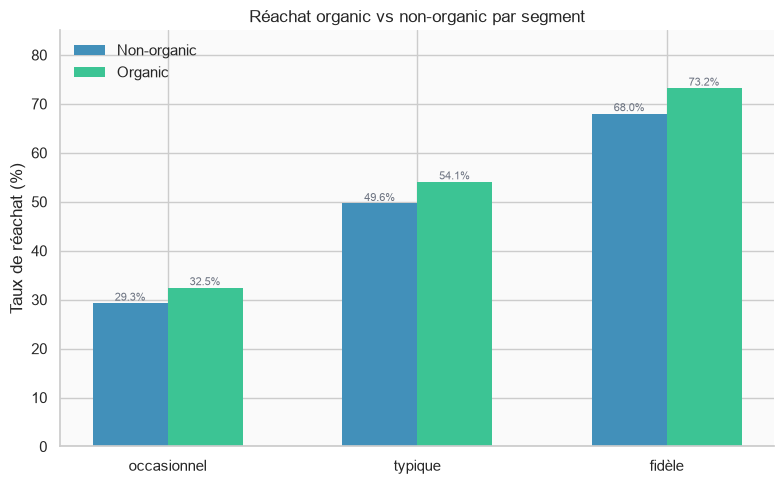

In [ ]:
data["is_organic"] = data["product_name"].str.contains(
    r"\borganic\b", case=False, na=False
).astype(int)

organic_segment = reorder_rate_by_group(data, ["is_organic", "customer_segment"])
organic_segment["label"] = organic_segment["is_organic"].map({0: "Non-organic", 1: "Organic"})

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(3)
width = 0.3

for i, (label, grp) in enumerate(organic_segment.groupby("label")):
    vals = grp.sort_values("customer_segment")["taux_reachat"] * 100
    color = COLORS["accent"] if label == "Organic" else COLORS["typique"]
    bars = ax.bar(x + i * width, vals, width, label=label, color=color, edgecolor="none")
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                f"{val:.1f}%", ha="center", fontsize=8, color=COLORS["grey"])

ax.set_xticks(x + width / 2)
ax.set_xticklabels(["occasionnel", "typique", "fidèle"])
ax.set_ylabel("Taux de réachat (%)")
ax.set_title("Réachat organic vs non-organic par segment")
ax.legend(frameon=False)
ax.set_ylim(0, 85)
plt.tight_layout()
plt.show()

### Interprétation

Selon l'analyse, l'écart organic/non organic est plus ou moins stable mais modeste.

Le bio est un facteur indépendant mais secondaire : il ajoute 2 à 4 points de réachat quel que soit le segment. L'écart se creuse légèrement chez les fidèles (+4.3 pts vs +2.5 pts), ce qui suggère une interaction modérée entre profil bio et fidélité, sans en être le moteur principal.

**Verdict sur l'hypothèse 2** : 
Le bio contribue marginalement au réachat. Ce n'est pas le profil bio qui crée la fidélité, mais c'est plutôt la fidélité qui s'accompagne d'un léger renforcement du choix bio.

## H3. Evolution du taux de réachat au fil des commandes (effet d'habitude)

Si le réachat augmente avec le numéro de commande, cela suggère un comportement d'habitude. Si le taux est stable dès la 2ème commande, c'est plus un trait du produit.

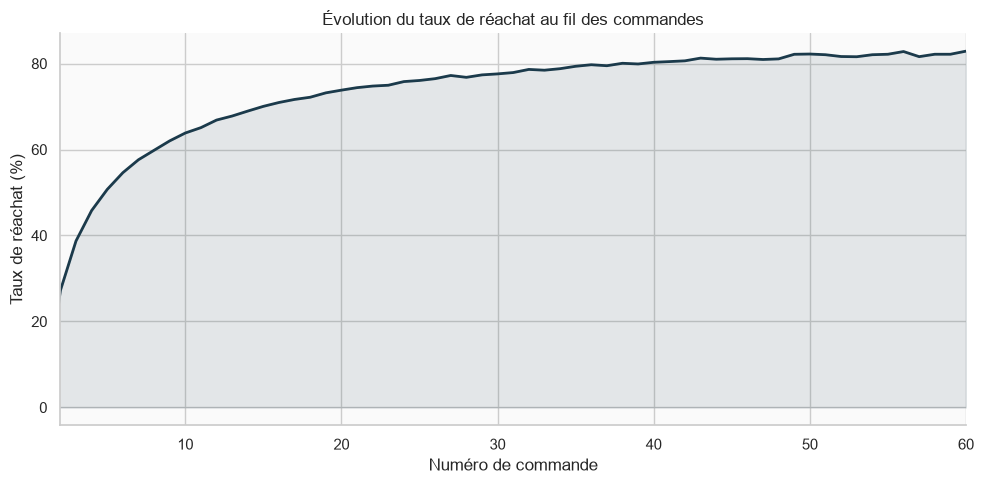

In [ ]:
evolution = reorder_evolution(data)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    evolution["order_number"],
    evolution["taux_reachat"] * 100,
    color=COLORS["fidèle"], linewidth=2
)
ax.fill_between(
    evolution["order_number"],
    evolution["taux_reachat"] * 100,
    alpha=0.1, color=COLORS["fidèle"]
)

ax.set_xlabel("Numéro de commande")
ax.set_ylabel("Taux de réachat (%)")
ax.set_title("Évolution du taux de réachat au fil des commandes")
ax.set_xlim(2, 60)
plt.tight_layout()
plt.show()

### Interprétation:

La courbe montre deux phases distinctes :

- **Phase d'installation (commandes 2 à 10)** : Le taux de réachat passe de ~28 % à ~65 %, soit un gain de +37 points en 8 commandes. C'est la période où le client découvre ses produits récurrents et installe ses habitudes.

- **Phase de plateau (après la commande 10-15)** : La croissance ralentit fortement. Le taux passe de 65 % à ~82 %, soit seulement +17 points sur les 50 commandes suivantes.

Le point d'inflexion se situe **autour de la 10ᵉ commande**. C'est là que la courbe passe de convexe à concave, autrement dit, c'est la commande après laquelle le gain marginal de réachat diminue. La 20ᵉ commande marque l'entrée dans le plateau de stabilisation.

**Verdict sur l'hypothèse 3** : L'effet d'habitude est confirmé. Les premières commandes sont le moment critique où le client construit son panier récurrent. Un client qui atteint la 10ᵉ commande a déjà internalisé l'essentiel de ses habitudes de réachat.

## Synthèse - Evolution du comportement d'achat

### Résultat d'analyse

Les trois analyses et leurs croisements convergent vers un modèle cohérent du comportement client sur la plateforme :

1. **La fidélité est un phénomène de fréquence, et non de volume.**
La taille du panier est stable (~8 articles) quel que soit le segment. Les fidèles ne dépensent pas plus par commande, mais ils commandent plus souvent.

2. **Le réachat est un marqueur de fidélité.**
L'écart occasionnel/fidèle se maintient sur tous les départements (+40 pts), ce qui prouve un comportement client structurel. L'effet catégorie (périssables plus rachetés) existe mais ne suffit pas à expliquer les écarts.

3. **Le bio est un signal, pas un moteur.**
Le bio semble davantage corrélé à un profil client déjà engagé qu'être une cause de fidélisation.

4. **Les 10 premières commandes sont la fenêtre critique.**
Le taux de réachat double entre la 2ème et la 10ème commande, puis se stabilise.
Si un client n'installe pas des habitudes à sa 10ème commande, il y a peu de chances qu'il le fera.

### Orientations business

Ces constats permettent de formuler trois axes d'action :

**1. Rétention rapide (commandes 3 à 10)** :
Concentrer les investissements marketing sur la fenêtre critique. Un bon de réduction ciblé à la 4ème commande, suivi d'un rappel personnalisé si le client dépasse son intervalle
habituel entre la 5ème et la 10ème.
L'objectif est de transformer un occasionnel en typique.

**2. Programme de fidélité basé sur la fréquence** :
Puisque le panier est stable mais la fréquence varie, des offres promotionnelles de type "10ème commande offerte" ou "livraison gratuite à partir de X commandes/mois" pourrait être envisagé.

**3. Disponibilité des produits ancres** :
Les dairy eggs, beverages et produce concentrent les taux de réachat les plus élevés.
Une rupture de stock sur ces catégories touche directement le cycle de réachat et risque de casser l'habitude.
Le suivi de disponibilité sur ces départements doit être prioritaire.

# IV. Temporalité

**Objectif** : 
Comprendre les habitudes temporelles de commande des clients (moment de la semaine et de la journée), afin d'identifier les périodes de forte affluence et les comportements de commandes répétées sur une même journée.

**Questions à traiter** :

1. Quand est-ce que les clients commandent le plus (heatmap jour × heure) ?
2. Les clients commandent-ils parfois plusieurs fois le même jour, et dans quelle proportion ?

**Impact business attendu** : 
Identifier les pics d'activité pour optimiser les ressources (stocks, personnel, capacité de livraison) aux moments clés, et détecter des comportements de commandes fractionnées pouvant révéler des frictions dans l'expérience d'achat.

## 1. Quand est-ce que les clients commandent le plus (heatmap jour × heure) ?

On mesure ici le nombre de **commandes passées** (pas de produits achetés) par jour de la semaine et heure de la journée. Comme `data` contient une ligne par produit dans une commande, on déduplique d'abord par `order_id` pour ne compter chaque commande qu'une seule fois, quelle que soit la taille de son panier. On réutilise la colonne `day_name`, déjà construite par `enrich_dataframe()`.

In [ ]:
orders_time = data.drop_duplicates(subset="order_id")[["order_id", "day_name", "order_hour_of_day"]]
heatmap_data = orders_time.groupby(["day_name", "order_hour_of_day"], observed=True).size().unstack(fill_value=0)

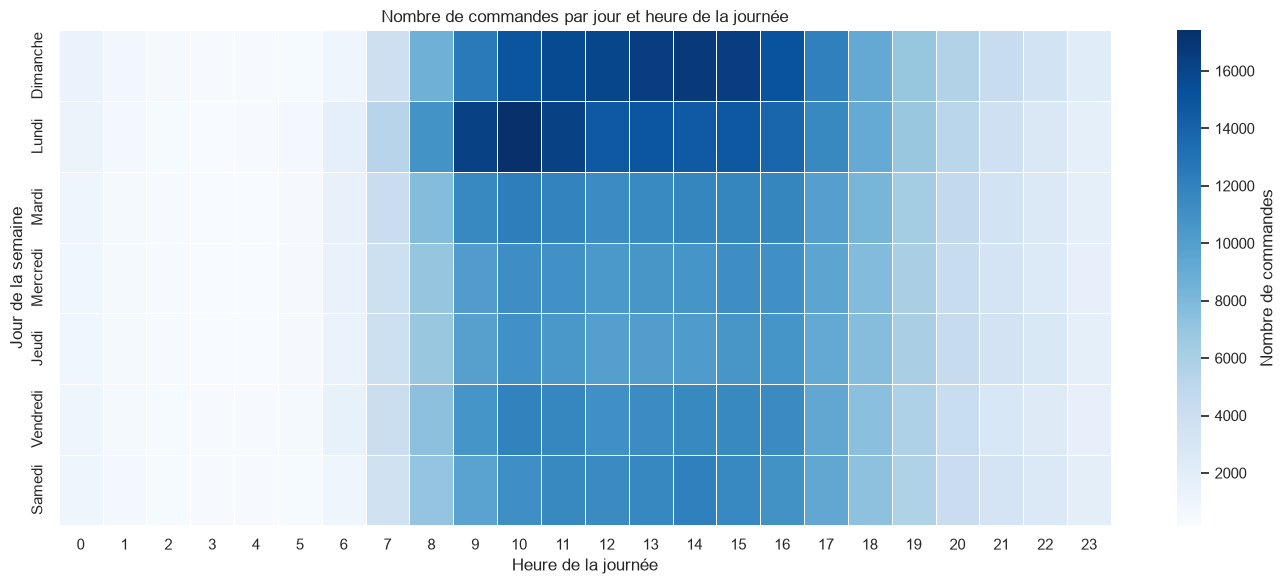

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    heatmap_data,
    cmap="Blues",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Nombre de commandes"},
    ax=ax
)
ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Jour de la semaine")
ax.set_title("Nombre de commandes par jour et heure de la journée")
plt.tight_layout()
plt.show()

**Réponse à la question :** 
Les commandes se concentrent nettement le week-end et en début de semaine, en particulier le **dimanche** et le **lundi**, avec un pic entre 9h et 16h environ. À l'inverse, les jours 
du milieu de semaine (mardi à vendredi) affichent une activité plus homogène et globalement plus faible. Les horaires de nuit (0h-6h) restent très peu actifs, tous les jours confondus.

**Implication business :** 
Ces créneaux de forte affluence (dimanche/lundi, milieu de journée) sont les moments à prioriser pour la disponibilité des stocks, la capacité de livraison, et le support 
client. À l'inverse, les heures creuses (nuit) pourraient être utilisées pour la maintenance technique ou les mises à jour de l'infrastructure sans impacter l'expérience utilisateur.

## 2. Les clients commandent-ils parfois plusieurs fois le même jour, et dans quelle proportion ?

La colonne `days_since_prior_order` indique le nombre de jours écoulés depuis la commande précédente du même utilisateur. Une valeur de 0 signifie que la commande précédente a eu lieu le même jour. On calcule cette proportion au niveau commande, en dédupliquant par `order_id`, et on la compare selon le segment client.

In [ ]:
same_day_by_segment = data.drop_duplicates(subset="order_id")[["order_id", "days_since_prior_order", "customer_segment"]]
same_day_by_segment["same_day"] = same_day_by_segment["days_since_prior_order"] == 0

same_day_count = same_day_by_segment["same_day"].sum()
total_orders = same_day_by_segment.shape[0]
same_day_pct = same_day_count / total_orders * 100

same_day_rate_by_segment = same_day_by_segment.groupby("customer_segment", observed=True)["same_day"].mean() * 100

print(f"Commandes le même jour que la précédente : {same_day_count:,} sur {total_orders:,} ({same_day_pct:.2f}%)")

Commandes le même jour que la précédente : 21,245 sur 1,064,689 (2.00%)


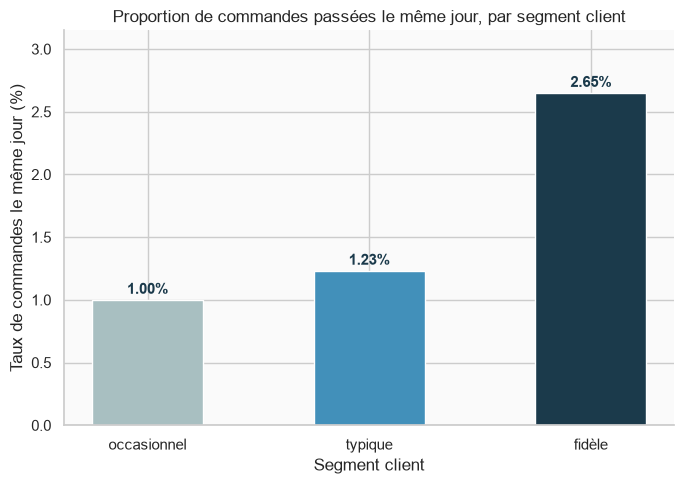

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
segments = same_day_rate_by_segment.index.tolist()
values = same_day_rate_by_segment.values
colors_bar = [COLORS[s] for s in segments]

bars = ax.bar(segments, values, color=colors_bar, width=0.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f"{val:.2f}%", ha="center", fontsize=11, fontweight="bold", color=COLORS["fidèle"])

ax.set_xlabel("Segment client")
ax.set_ylabel("Taux de commandes le même jour (%)")
ax.set_title("Proportion de commandes passées le même jour, par segment client")
ax.set_ylim(0, max(values) + 0.5)
plt.tight_layout()
plt.show()

**Résultat :** 
2,00% des commandes sont passées le même jour que la commande précédente de l'utilisateur (21 245 commandes sur 1 064 689). 
Ce taux varie selon le segment client :

Segment - Taux de commandes le même jour
Occasionnel - 1,00% 
Typique - 1,23%
Fidèle - 2,65% 

**Interprétation :** 
Les clients fidèles sont environ 2,6 fois plus susceptibles de recommander le même jour que les clients occasionnels. 
Cet écart peut s'expliquer en partie par un effet mécanique (plus de commandes au total = plus d'occasions statistiques de tomber sur ce cas de figure), mais pourrait aussi révéler un vrai comportement : des clients qui complètent une commande oubliée, ou qui fractionnent volontairement leurs achats en plusieurs commandes rapprochées.

**Implication business :** 
Ce phénomène, bien que minoritaire, pourrait signaler des frictions dans l'expérience de commande (produit oublié, besoin urgent après coup) plutôt qu'un choix délibéré. Plutôt que de faciliter une seconde commande, il serait pertinent de proposer une fenêtre de modification (par exemple 15 minutes après validation) permettant au client d'ajouter un produit oublié directement à sa commande initiale. 
Cela répondrait à la cause probable du phénomène tout en évitant des frais de livraison et de traitement dupliqués, aussi bien pour le client que pour la plateforme.

## Conclusion générale — Temporalité

Les deux analyses montrent deux choses complémentaires. D'abord, on peut prévoir globalement quand les commandes arrivent : surtout le dimanche et le lundi, en journée (Q1). Ensuite, on voit que ce rythme n'est pas exactement le même pour tout le monde : les clients fidèles recommandent plus souvent le même jour que les occasionnels, souvent par oubli d'un produit (Q2).

**Recommandation :** 
La plateforme peut planifier ses stocks et sa capacité de livraison à l'avance en se basant sur les créneaux identifiés. Pour réduire les commandes multiples liées à un oubli, une 
fenêtre de modification après validation (voir Q2) serait une piste concrète à explorer.